# **Data Visualization Game**

# 1. **Import**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 12

# **2. Mount Google Drive**

In [4]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Data Visualization Game/vgsales_clean.csv'

df = pd.read_csv(file_path)

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)

display(df.head())

Mounted at /content/drive
Dataset berhasil dibaca!
Ukuran dataset: (16291, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


# **3. Memeriksa Struktur Dataset**

In [5]:
print("Informasi Dataset:")
df.info()

print("\nJumlah Missing Value:")
print(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16291 entries, 0 to 16290
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  object 
 2   Platform      16291 non-null  object 
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  object 
 5   Publisher     16291 non-null  object 
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.4+ MB

Jumlah Missing Value:
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

Jumlah Data Dupl

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
mean,8290.190228,2006.405561,0.265647,0.147731,0.078833,0.048426,0.540910
std,4792.654450,5.832412,0.822432,0.509303,0.311879,0.190083,1.567345
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4132.500000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8292.000000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12439.500000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


# **4. Prepare Data Visualization**

In [6]:
sales_columns = [
    "NA_Sales",
    "EU_Sales",
    "JP_Sales",
    "Other_Sales",
    "Global_Sales"
]

df[sales_columns] = df[sales_columns].apply(
    pd.to_numeric, errors="coerce"
)

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

df_sales = df.dropna(
    subset=["Name", "Platform", "Genre", "Global_Sales"]
).copy()

df_year = df_sales.dropna(subset=["Year"]).copy()
df_year = df_year[df_year["Year"].between(1980, 2020)]

print("Jumlah data untuk visualisasi:", len(df_sales))
print("Jumlah data dengan tahun valid:", len(df_year))

Jumlah data untuk visualisasi: 16291
Jumlah data dengan tahun valid: 16291


# **Visualisasi Data**

# **5. Penjualan Berdasarkan Platform (Horizontal Bar Chart)**

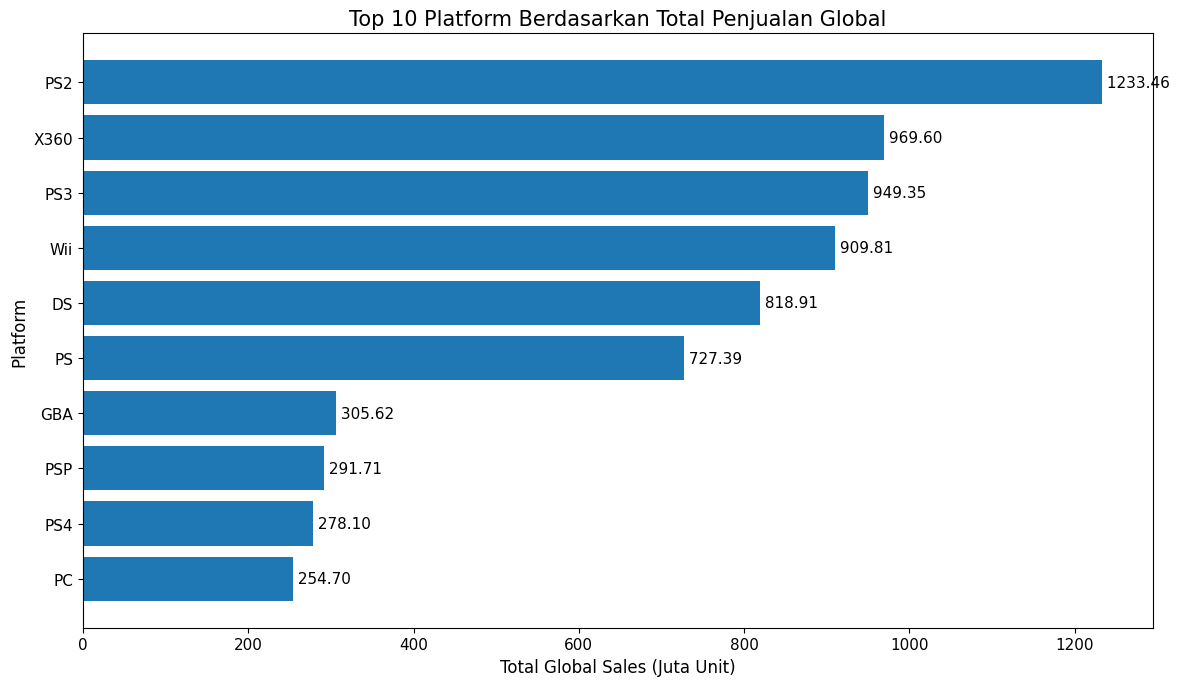

In [7]:
platform_sales = (
    df_sales.groupby("Platform")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))
bars = plt.barh(
    platform_sales.index,
    platform_sales.values
)

plt.title("Top 10 Platform Berdasarkan Total Penjualan Global")
plt.xlabel("Total Global Sales (Juta Unit)")
plt.ylabel("Platform")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.2f}",
        va="center"
    )

plt.tight_layout()
plt.show()

# **6. Tren Penjualan Berdasarkan Tahun Rilis (Line Chart)**

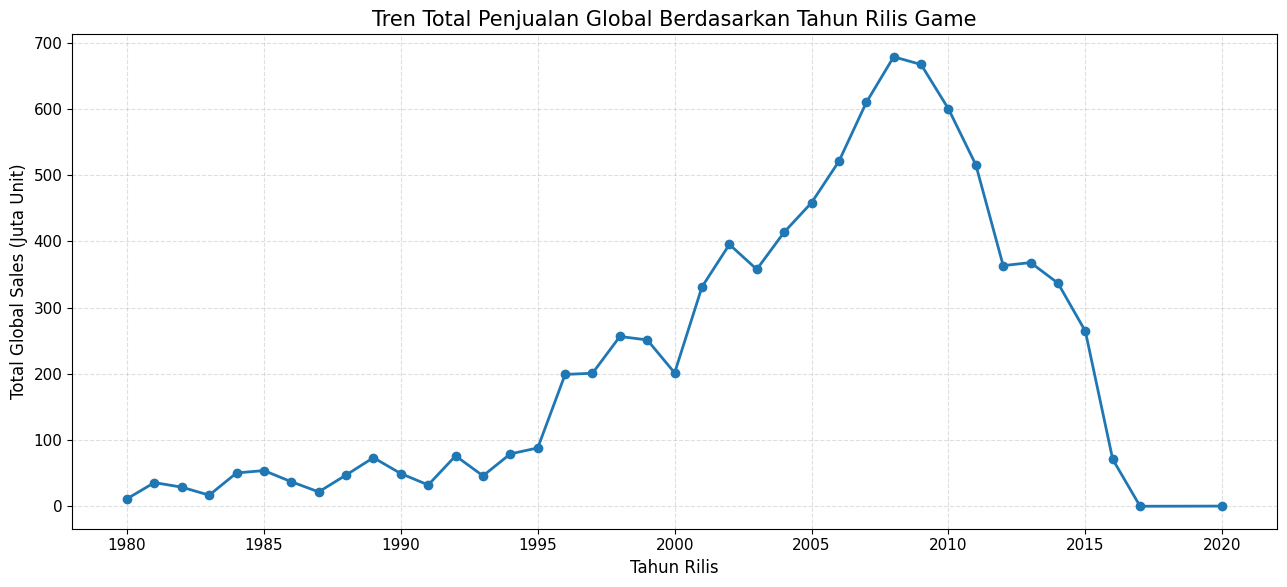

In [8]:
year_sales = (
    df_year.groupby("Year")["Global_Sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(13, 6))
plt.plot(
    year_sales.index,
    year_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Tren Total Penjualan Global Berdasarkan Tahun Rilis Game")
plt.xlabel("Tahun Rilis")
plt.ylabel("Total Global Sales (Juta Unit)")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# **7. Distribusi Penjualan Per Wilayah (Donut Chart)**

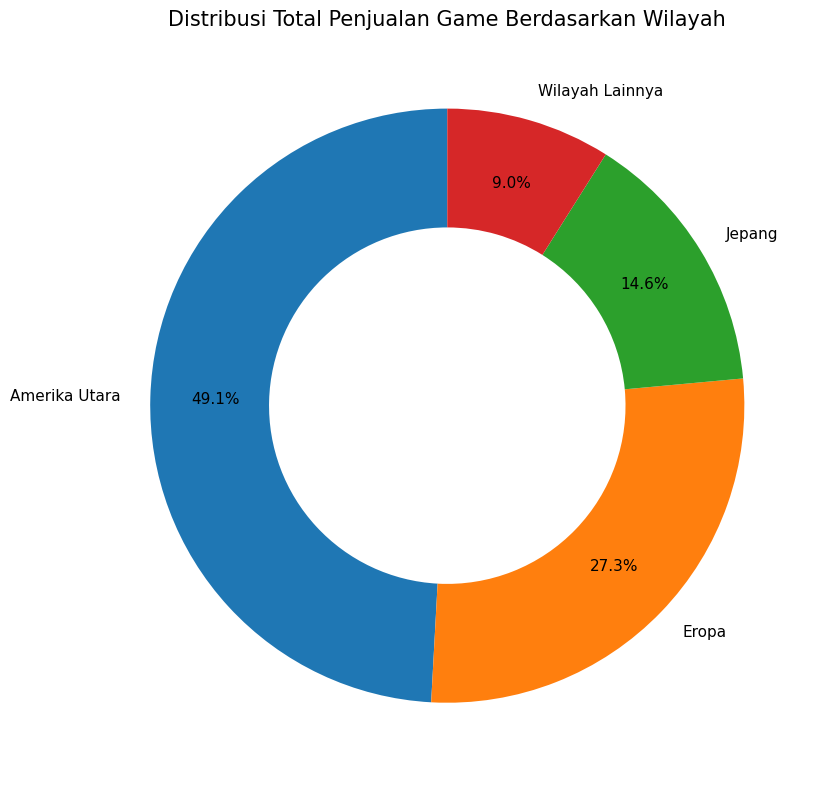

,Total Sales (Juta Unit)
Amerika Utara,4327.65
Eropa,2406.69
Jepang,1284.27
Wilayah Lainnya,788.91


In [9]:
region_columns = {
    "Amerika Utara": "NA_Sales",
    "Eropa": "EU_Sales",
    "Jepang": "JP_Sales",
    "Wilayah Lainnya": "Other_Sales"
}

region_sales = pd.Series({
    region: df_sales[column].sum()
    for region, column in region_columns.items()
})

plt.figure(figsize=(9, 8))

plt.pie(
    region_sales,
    labels=region_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.4}
)

plt.title("Distribusi Total Penjualan Game Berdasarkan Wilayah")
plt.tight_layout()
plt.show()

display(
    region_sales.rename("Total Sales (Juta Unit)").to_frame()
)

# **8. Game Dengan Penjualan Tertinggi (Lollipop Chart)**

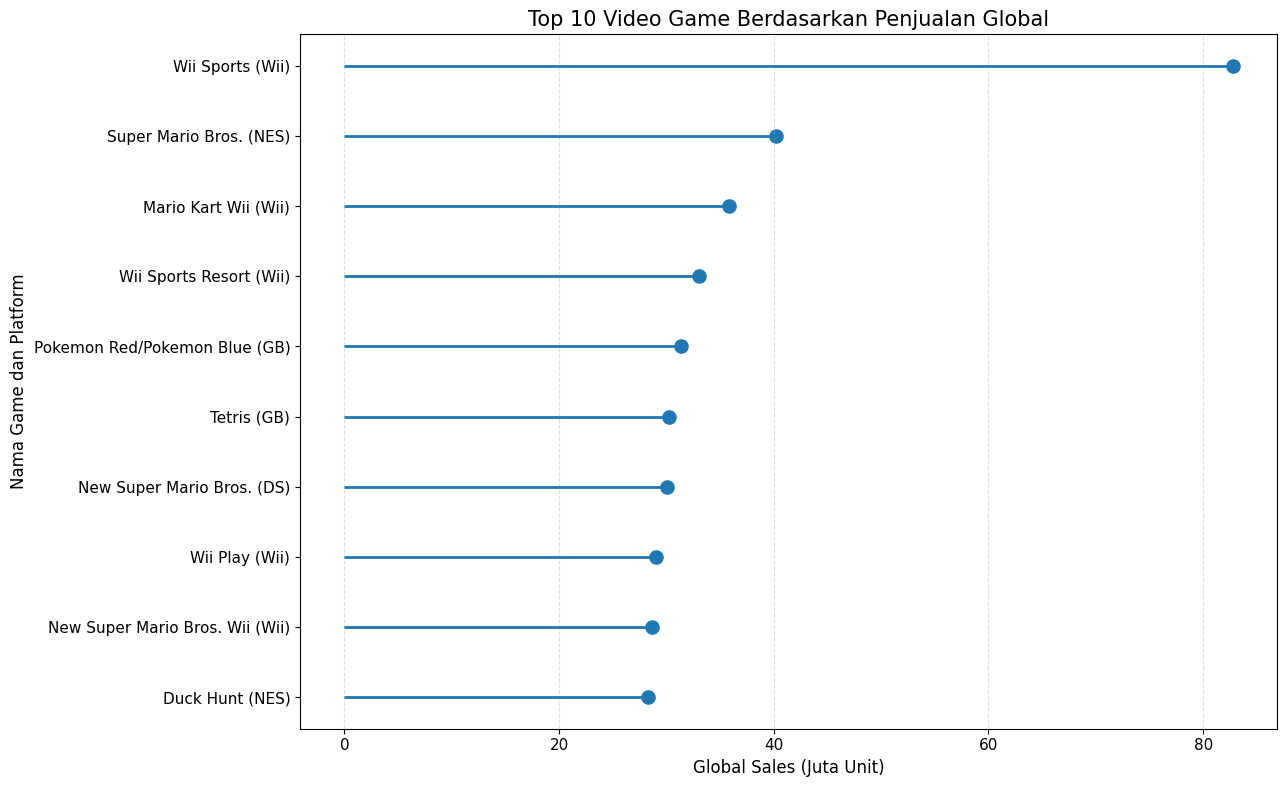

In [10]:
top_games = (
    df_sales.nlargest(10, "Global_Sales")
    .copy()
    .sort_values("Global_Sales")
)

top_games["Game"] = (
    top_games["Name"].astype(str)
    + " ("
    + top_games["Platform"].astype(str)
    + ")"
)

plt.figure(figsize=(13, 8))

plt.hlines(
    y=top_games["Game"],
    xmin=0,
    xmax=top_games["Global_Sales"],
    linewidth=2
)

plt.scatter(
    top_games["Global_Sales"],
    top_games["Game"],
    s=90
)

plt.title("Top 10 Video Game Berdasarkan Penjualan Global")
plt.xlabel("Global Sales (Juta Unit)")
plt.ylabel("Nama Game dan Platform")
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# **9. Penjualan Berdasarkan Genre (Treemap)**

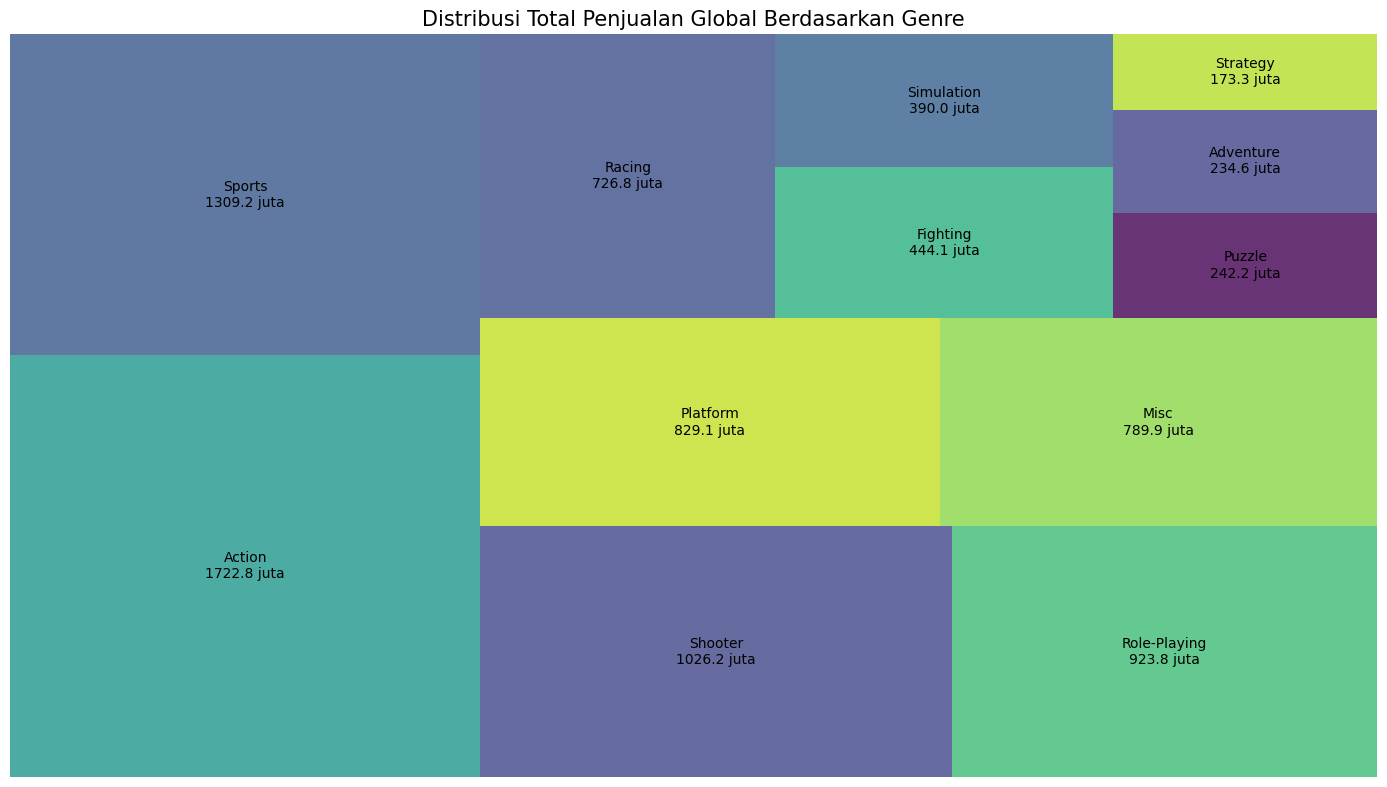

In [11]:
import squarify

genre_sales = (
    df_sales.groupby("Genre")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

labels = [
    f"{genre}\n{sales:.1f} juta"
    for genre, sales in genre_sales.items()
]

plt.figure(figsize=(14, 8))

squarify.plot(
    sizes=genre_sales.values,
    label=labels,
    alpha=0.8,
    text_kwargs={"fontsize": 10}
)

plt.title("Distribusi Total Penjualan Global Berdasarkan Genre")
plt.axis("off")
plt.tight_layout()
plt.show()

# **10. Ringkasan Hasil Data Visualization**

In [12]:
print("RINGKASAN HASIL DATA VISUALIZATION")
print("=" * 45)

best_platform = platform_sales.idxmax()
best_platform_sales = platform_sales.max()

best_year = year_sales.idxmax()
best_year_sales = year_sales.max()

best_region = region_sales.idxmax()
best_region_sales = region_sales.max()

best_game = df_sales.loc[
    df_sales["Global_Sales"].idxmax()
]

best_genre = genre_sales.idxmax()
best_genre_sales = genre_sales.max()

print(
    f"Platform dengan penjualan tertinggi: "
    f"{best_platform} ({best_platform_sales:.2f} juta unit)"
)

print(
    f"Tahun rilis dengan total penjualan tertinggi: "
    f"{int(best_year)} ({best_year_sales:.2f} juta unit)"
)

print(
    f"Wilayah dengan total penjualan tertinggi: "
    f"{best_region} ({best_region_sales:.2f} juta unit)"
)

print(
    f"Game dengan penjualan tertinggi: "
    f"{best_game['Name']} - {best_game['Platform']} "
    f"({best_game['Global_Sales']:.2f} juta unit)"
)

print(
    f"Genre dengan total penjualan tertinggi: "
    f"{best_genre} ({best_genre_sales:.2f} juta unit)"
)

RINGKASAN HASIL DATA VISUALIZATION
Platform dengan penjualan tertinggi: PS2 (1233.46 juta unit)
Tahun rilis dengan total penjualan tertinggi: 2008 (678.90 juta unit)
Wilayah dengan total penjualan tertinggi: Amerika Utara (4327.65 juta unit)
Game dengan penjualan tertinggi: Wii Sports - Wii (82.74 juta unit)
Genre dengan total penjualan tertinggi: Action (1722.84 juta unit)


# 11. **Kesimpulan**

In [13]:
print("KESIMPULAN")

print(
    f"1. Platform dengan total penjualan global tertinggi "
    f"di antara 10 platform teratas adalah {best_platform}."
)

print(
    f"2. Tahun rilis dengan akumulasi penjualan terbesar "
    f"dalam data adalah {int(best_year)}."
)

print(
    f"3. Wilayah dengan kontribusi penjualan terbesar "
    f"adalah {best_region}."
)

print(
    f"4. Game dengan penjualan global tertinggi adalah "
    f"{best_game['Name']} pada platform {best_game['Platform']}."
)

print(
    f"5. Genre dengan total penjualan global tertinggi "
    f"adalah {best_genre}."
)

print(
    "\nKesimpulan ini menggambarkan pola pada dataset yang dianalisis, "
    "bukan keseluruhan pasar video game."
)

KESIMPULAN
1. Platform dengan total penjualan global tertinggi di antara 10 platform teratas adalah PS2.
2. Tahun rilis dengan akumulasi penjualan terbesar dalam data adalah 2008.
3. Wilayah dengan kontribusi penjualan terbesar adalah Amerika Utara.
4. Game dengan penjualan global tertinggi adalah Wii Sports pada platform Wii.
5. Genre dengan total penjualan global tertinggi adalah Action.

Kesimpulan ini menggambarkan pola pada dataset yang dianalisis, bukan keseluruhan pasar video game.
